In [1]:
import os

# Check files inside the data folder
data_folder = "../data"

print("Files available in the data folder:\n")

for root, dirs, files in os.walk(data_folder):
    for file in files:
        print(os.path.join(root, file))


Files available in the data folder:

../data\bank+marketing\bank-additional.zip
../data\bank+marketing\bank.zip
../data\bank+marketing\bank\bank-full.csv
../data\bank+marketing\bank\bank-names.txt
../data\bank+marketing\bank\bank.csv
../data\bank+marketing\bank-additional\bank-additional\.DS_Store
../data\bank+marketing\bank-additional\bank-additional\.Rhistory
../data\bank+marketing\bank-additional\bank-additional\bank-additional-full.csv
../data\bank+marketing\bank-additional\bank-additional\bank-additional-names.txt
../data\bank+marketing\bank-additional\bank-additional\bank-additional.csv
../data\bank+marketing\bank-additional\__MACOSX\._bank-additional
../data\bank+marketing\bank-additional\__MACOSX\bank-additional\._.DS_Store


In [2]:
# STEP 5: Load the Bank Marketing dataset

import pandas as pd
import numpy as np

# Dataset path
file_path = "../data/bank+marketing/bank/bank-full.csv"

# Load dataset
df = pd.read_csv(file_path, sep=";")

# Display basic information
print("Dataset loaded successfully!")

print("\nDataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nTarget distribution:")
print(df["y"].value_counts())

print("\nTarget percentages:")
print(df["y"].value_counts(normalize=True) * 100)


Dataset loaded successfully!

Dataset shape: (45211, 17)

First 5 rows:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no



Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 

Missing values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Duplicate records: 0

Target distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Numerical feature summary:


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000



Numerical columns: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']


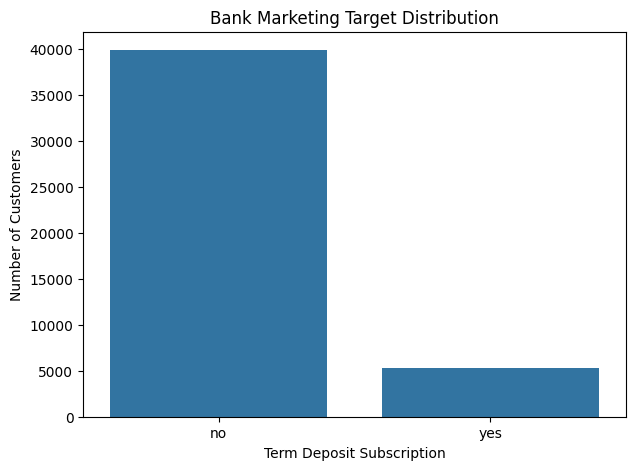

In [3]:

# STEP 6: Exploratory Data Analysis

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Check missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# 3. Target distribution
print("\nTarget distribution:")
print(df["y"].value_counts())

# 4. Numeric feature summary
print("\nNumerical feature summary:")
display(df.describe())

# 5. Identify numerical and categorical columns
numeric_columns = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_columns = df.select_dtypes(include=["object"]).columns.tolist()

print("\nNumerical columns:", numeric_columns)
print("\nCategorical columns:", categorical_columns)

# 6. Visualise target distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="y")

plt.title("Bank Marketing Target Distribution")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")

plt.show()


In [4]:

# STEP 7: Data preprocessing

import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# 1. Remove duration to prevent data leakage
df_model = df.drop(columns=["duration"]).copy()

# 2. Separate features and target
X = df_model.drop(columns=["y"])
y = df_model["y"].map({"no": 0, "yes": 1})

# 3. Identify feature types
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

# 4. Split into training, validation and testing sets
# 70% training, 15% validation, 15% testing

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nDataset split:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

# 5. Create preprocessing pipelines

numeric_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# 6. Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)

# Convert to dense arrays for ANN training
X_train_processed = np.asarray(X_train_processed, dtype=np.float32)
X_val_processed = np.asarray(X_val_processed, dtype=np.float32)
X_test_processed = np.asarray(X_test_processed, dtype=np.float32)

# Convert targets to NumPy arrays
y_train = y_train.to_numpy(dtype=np.float32)
y_val = y_val.to_numpy(dtype=np.float32)
y_test = y_test.to_numpy(dtype=np.float32)

print("\nPreprocessing completed!")

print("Training data:", X_train_processed.shape)
print("Validation data:", X_val_processed.shape)
print("Testing data:", X_test_processed.shape)
print("Number of input features after encoding:", X_train_processed.shape[1])


Numerical features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Dataset split:
Training: (31647, 15)
Validation: (6782, 15)
Testing: (6782, 15)

Preprocessing completed!
Training data: (31647, 50)
Validation data: (6782, 50)
Testing data: (6782, 50)
Number of input features after encoding: 50


Logistic Regression training completed!

LOGISTIC REGRESSION - VALIDATION RESULTS
-----------------------------------------
Accuracy:  0.7566
Precision: 0.2688
Recall:    0.6272
F1 Score:  0.3763
ROC-AUC:   0.7720
PR-AUC:    0.4162

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.94      0.77      0.85      5988
   Subscription       0.27      0.63      0.38       794

       accuracy                           0.76      6782
      macro avg       0.60      0.70      0.61      6782
   weighted avg       0.86      0.76      0.79      6782



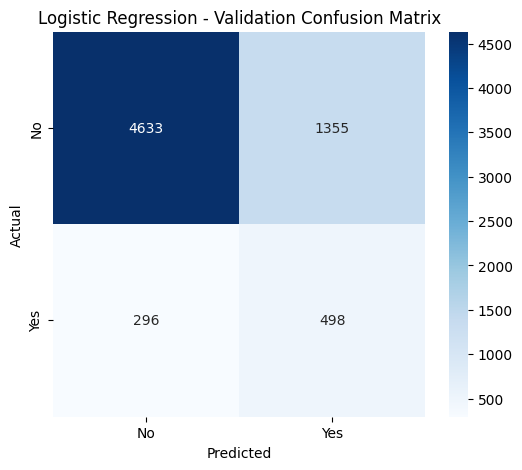

In [5]:

# STEP 8: Baseline Model - Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create Logistic Regression model
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# 2. Train the model
lr_model.fit(X_train_processed, y_train)

print("Logistic Regression training completed!")

# 3. Predict validation data
y_val_pred_lr = lr_model.predict(X_val_processed)

y_val_prob_lr = lr_model.predict_proba(X_val_processed)[:, 1]

# 4. Evaluate model
lr_accuracy = accuracy_score(y_val, y_val_pred_lr)
lr_precision = precision_score(y_val, y_val_pred_lr, zero_division=0)
lr_recall = recall_score(y_val, y_val_pred_lr, zero_division=0)
lr_f1 = f1_score(y_val, y_val_pred_lr, zero_division=0)
lr_roc_auc = roc_auc_score(y_val, y_val_prob_lr)
lr_pr_auc = average_precision_score(y_val, y_val_prob_lr)

print("\nLOGISTIC REGRESSION - VALIDATION RESULTS")
print("-----------------------------------------")
print(f"Accuracy:  {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall:    {lr_recall:.4f}")
print(f"F1 Score:  {lr_f1:.4f}")
print(f"ROC-AUC:   {lr_roc_auc:.4f}")
print(f"PR-AUC:    {lr_pr_auc:.4f}")

# 5. Classification report
print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_lr,
    target_names=["No Subscription", "Subscription"],
    zero_division=0
))

# 6. Confusion matrix
cm = confusion_matrix(y_val, y_val_pred_lr)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Logistic Regression - Validation Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [6]:

# STEP 9: ANN Model 1 - One Hidden Layer

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

# Set random seeds
tf.keras.utils.set_random_seed(42)

# 1. Create ANN architecture
ann_model_1 = Sequential([
    Input(shape=(X_train_processed.shape[1],)),

    Dense(32, activation="relu"),

    Dense(1, activaion="sigmoid")
])

# 2. Compile model
ann_model_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

# 3. Display architecture
ann_model_1.summary()

# 4. Handle class imbalance
class_weights = {
    0: 0.5,
    1: 3.77
}

# 5. Early stopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# 6. Train model
history_1 = ann_model_1.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=50,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

print("\nANN Model 1 training completed!")



[TensorFlow DLL Diagnostic] Analyzing: c:\Users\Manjitha Kaluarachch\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow\python\_pywrap_tensorflow_internal.pyd
[Error] Failed to load _pywrap_tensorflow_common.dll: INITIALIZATION FAILED (0x45A) - The DLL's DllMain returned false.
    Hint: This often happens if your CPU lacks required instructions (like AVX/AVX2)
    or if the Microsoft Visual C++ Redistributable is outdated/missing.


ImportError: Traceback (most recent call last):
  File "c:\Users\Manjitha Kaluarachch\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow\python\pywrap_tensorflow.py", line 74, in <module>
    from tensorflow.python._pywrap_tensorflow_internal import *
ImportError: DLL load failed while importing _pywrap_tensorflow_internal: A dynamic link library (DLL) initialization routine failed.


Failed to load the native TensorFlow runtime.
See https://www.tensorflow.org/install/errors for some common causes and solutions.
If you need help, create an issue at https://github.com/tensorflow/tensorflow/issues and include the entire stack trace above this error message.

In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

# Set random seed
tf.keras.utils.set_random_seed(42)

# Build ANN Model 1
ann_model_1 = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

# Compile model
ann_model_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

# Display architecture
ann_model_1.summary()

# Handle class imbalance
class_weights = {
    0: 0.5,
    1: 3.77
}

# Early stopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train model
history_1 = ann_model_1.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=50,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

print("ANN Model 1 training completed!")


[TensorFlow DLL Diagnostic] Analyzing: c:\Users\Manjitha Kaluarachch\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow\python\_pywrap_tensorflow_internal.pyd
[Error] Failed to load _pywrap_tensorflow_common.dll: INITIALIZATION FAILED (0x45A) - The DLL's DllMain returned false.
    Hint: This often happens if your CPU lacks required instructions (like AVX/AVX2)
    or if the Microsoft Visual C++ Redistributable is outdated/missing.


ImportError: Traceback (most recent call last):
  File "c:\Users\Manjitha Kaluarachch\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow\python\pywrap_tensorflow.py", line 74, in <module>
    from tensorflow.python._pywrap_tensorflow_internal import *
ImportError: DLL load failed while importing _pywrap_tensorflow_internal: A dynamic link library (DLL) initialization routine failed.


Failed to load the native TensorFlow runtime.
See https://www.tensorflow.org/install/errors for some common causes and solutions.
If you need help, create an issue at https://github.com/tensorflow/tensorflow/issues and include the entire stack trace above this error message.

In [2]:
import sys
print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: c:\Users\Manjitha Kaluarachch\AppData\Local\Programs\Python\Python312\python.exe
Python version: 3.12.1 (tags/v3.12.1:2305ca5, Dec  7 2023, 22:03:25) [MSC v.1937 64 bit (AMD64)]


In [1]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

result = tf.reduce_sum(tf.random.normal([100, 100]))

print("Test result:", result)


[TensorFlow DLL Diagnostic] Analyzing: c:\Users\Manjitha Kaluarachch\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow\python\_pywrap_tensorflow_internal.pyd
[Error] Failed to load _pywrap_tensorflow_common.dll: INITIALIZATION FAILED (0x45A) - The DLL's DllMain returned false.
    Hint: This often happens if your CPU lacks required instructions (like AVX/AVX2)
    or if the Microsoft Visual C++ Redistributable is outdated/missing.


ImportError: Traceback (most recent call last):
  File "c:\Users\Manjitha Kaluarachch\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow\python\pywrap_tensorflow.py", line 74, in <module>
    from tensorflow.python._pywrap_tensorflow_internal import *
ImportError: DLL load failed while importing _pywrap_tensorflow_internal: A dynamic link library (DLL) initialization routine failed.


Failed to load the native TensorFlow runtime.
See https://www.tensorflow.org/install/errors for some common causes and solutions.
If you need help, create an issue at https://github.com/tensorflow/tensorflow/issues and include the entire stack trace above this error message.